# 03 · Submission

Memuat pipeline final `models/pipeline_lgbm.pkl` (dibuat oleh `02_modeling.ipynb` atau `python -m scripts.train`),
memprediksi data test, memvalidasi format, dan menyimpan `submissions/submission.csv`.

Pipeline menghitung fitur berbasis label test dari **seluruh** label train, lalu memakai bobot kelas yang dipilih di OOF.

In [1]:
import sys, os, time, warnings, json
sys.path.insert(0, os.path.abspath('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)

from scripts.preprocess import SEED, GRADES, CAT_COLS, load_data, add_unsupervised_features

np.random.seed(SEED)
DATA_DIR = '../data'
FIG_DIR = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)
T0 = time.time()

# Palet: rampa biru berurutan untuk grade 1 -> 5 (target ordinal)
GRADE_COLORS = ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281']
ACCENT, ACCENT2 = '#2a78d6', '#eb6834'
mpl.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#8a8984', 'axes.titleweight': 'bold', 'font.size': 10})

def savefig(name):
    # simpan figur ke reports/figures lalu tampilkan
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/{name}.png', dpi=120, bbox_inches='tight'); plt.show()

import joblib
from scripts.predict import make_submission

In [2]:
train, test, y = load_data(DATA_DIR)
pipe = joblib.load('../models/pipeline_lgbm.pkl')
sub = make_submission(pipe, train, test)   # termasuk validasi format
os.makedirs('../submissions', exist_ok=True)
sub.to_csv('../submissions/submission.csv', index=False)
print('tersimpan:', sub.shape); display(sub.head())
sample = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')
print('kolom sama dengan sample_submission:', list(sub.columns) == list(sample.columns),
      '| building_id sama:', set(sub.building_id) == set(sample.building_id))

tersimpan: (228629, 2)


,building_id,damage_grade
0,122207000141,2
1,284909000871,5
2,241904000231,4
3,248308000891,2
4,300405002981,4


kolom sama dengan sample_submission: True | building_id sama: True


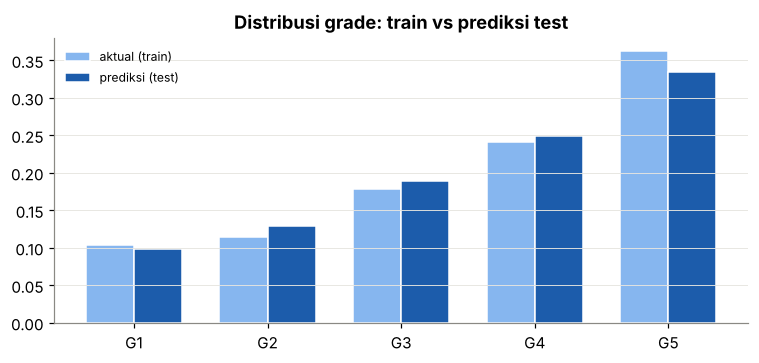

In [3]:
dp = sub.damage_grade.value_counts(normalize=True).sort_index()
da = pd.Series(y).value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(7, 3.4)); xx = np.arange(5)
ax.bar(xx - 0.18, da.values, 0.36, color='#86b6ef', label='aktual (train)', edgecolor='white')
ax.bar(xx + 0.18, dp.values, 0.36, color='#1c5cab', label='prediksi (test)', edgecolor='white')
ax.set_xticks(xx, [f'G{g}' for g in GRADES]); ax.set_title('Distribusi grade: train vs prediksi test')
ax.legend(frameon=False, fontsize=8); ax.grid(axis='x', visible=False)
savefig('distribusi_prediksi_test')

Format yang dikirim: `building_id`, `damage_grade` integer 1–5. Format ini sudah diterima Kaggle
(skor publik versi sebelumnya 0.5998). `sample_submission.csv` memakai teks `Grade k`; kalau panitia meminta
format teks, ubah dengan `sub['damage_grade'] = 'Grade ' + sub['damage_grade'].astype(str)`.